# Session 4 — Pose Estimation & Movement Analysis
## From Body Landmarks to Movement

In this session you will learn how to turn a person in an image into a structured set of body landmarks, measure distances and joint angles, describe body states, track movement across frames, and finally build a real-time pose analyzer (including a squat counter).


---
## Section 1 — Connecting the Sessions

| Session | Focus | Pipeline |
|---------|-------|----------|
| 2 | Hand | Hand → Landmarks → Features → Gesture → Action |
| 3 | Face | Face → Landmarks → Features → Facial State → Action |
| 4 | Body | Body → Landmarks → Features → Pose / Movement → Action |

**Question:** What happens if we apply the same idea to the entire human body?

That is exactly what pose estimation does.

---
## Section 2 — What Is Pose Estimation?

**Pose Estimation** answers: *Where are the key body points?*

MediaPipe Pose Landmarker returns **33 body landmarks**.  

### Important landmarks we will use

| Index | Name | Index | Name |
|-------|------|-------|------|
| 11 | Left shoulder | 12 | Right shoulder |
| 13 | Left elbow | 14 | Right elbow |
| 15 | Left wrist | 16 | Right wrist |
| 23 | Left hip | 24 | Right hip |
| 25 | Left knee | 26 | Right knee |
| 27 | Left ankle | 28 | Right ankle |

We do not need to memorize all 33 points. We focus on the ones required for geometry and movement.

### Reference: Body Landmarks Diagram

![MediaPipe Pose Landmarks](pose_landmarks_index.png)

*Official MediaPipe Pose Landmarks (33 points). Source: Google MediaPipe documentation.*

---
## Section 3 — First Pose Landmark Detection

We start with a **single image**. Webcam processing comes later.

In [ ]:
# Cell 1 — Imports
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from mediapipe.tasks.python.vision import drawing_utils, drawing_styles

print("MediaPipe version:", mp.__version__)

In [ ]:
# Cell 2 — Model setup (MediaPipe Tasks API)
from pathlib import Path
import urllib.request

MODEL_PATH = Path("pose_landmarker_lite.task")
MODEL_URL = (
    "https://storage.googleapis.com/mediapipe-models/"
    "pose_landmarker/pose_landmarker_lite/float16/1/pose_landmarker_lite.task"
)

if not MODEL_PATH.exists():
    print("Downloading Pose Landmarker model...")
    urllib.request.urlretrieve(MODEL_URL, MODEL_PATH)
    print("Download complete.")

BaseOptions = python.BaseOptions
PoseLandmarker = vision.PoseLandmarker
PoseLandmarkerOptions = vision.PoseLandmarkerOptions
VisionRunningMode = vision.RunningMode

options = PoseLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=str(MODEL_PATH)),
    running_mode=VisionRunningMode.IMAGE,
    num_poses=1
)

landmarker = PoseLandmarker.create_from_options(options)
print("Pose Landmarker ready.")

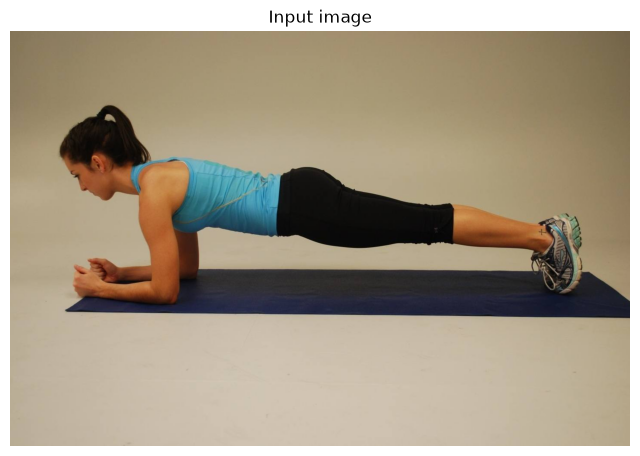

Image shape: (964, 1440, 3)


In [10]:
# Cell 3 — Load a sample image
# Place a full-body photo named sample_pose.jpg in the current directory
IMAGE_PATH = "sample_pose.jpg"
#IMAGE_PATH = "sample_pose - Copy.jpg"
mp_image = mp.Image.create_from_file(IMAGE_PATH)
rgb = mp_image.numpy_view()

plt.figure(figsize=(8, 6))
plt.imshow(rgb)
plt.title("Input image")
plt.axis("off")
plt.show()
print("Image shape:", rgb.shape)

In [11]:
# Cell 4 — Run pose detection
detection_result = landmarker.detect(mp_image)

if detection_result.pose_landmarks:
    print(f"Detected {len(detection_result.pose_landmarks)} pose(s)")
    print(f"Number of landmarks: {len(detection_result.pose_landmarks[0])}")
else:
    print("No pose detected. Try a different image with a clearly visible person.")



"""
for x in detection_result.pose_landmarks[0]:
    print(x)
"""

Detected 1 pose(s)
Number of landmarks: 33


'\nfor x in detection_result.pose_landmarks[0]:\n    print(x)\n'

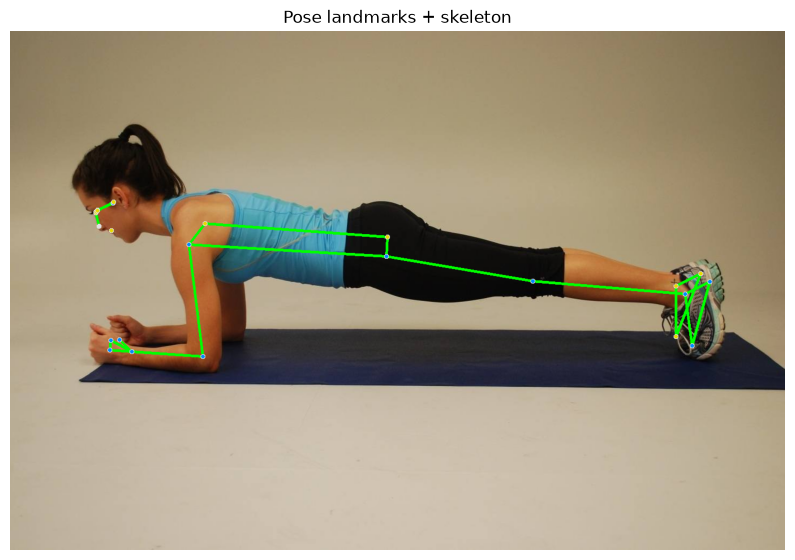

In [17]:
# Cell 5 — Visualize landmarks + skeleton
def draw_pose(rgb_image, detection_result):
    annotated = np.copy(rgb_image)
    pose_landmark_style = drawing_styles.get_default_pose_landmarks_style()
    connection_style = drawing_utils.DrawingSpec(color=(0, 255, 0), thickness=4)

    for pose_landmarks in detection_result.pose_landmarks:
        drawing_utils.draw_landmarks(
            image=annotated,
            landmark_list=pose_landmarks,
            connections=vision.PoseLandmarksConnections.POSE_LANDMARKS,
            landmark_drawing_spec=pose_landmark_style,
            connection_drawing_spec=connection_style
        )
    return annotated

if detection_result.pose_landmarks:
    annotated = draw_pose(rgb, detection_result)
    plt.figure(figsize=(10, 8))
    plt.imshow(annotated)
    plt.title("Pose landmarks + skeleton")
    plt.axis("off")
    plt.show()
else:
    print("Nothing to draw.")

**Checkpoint**  
What information does a single landmark give us?  
What extra information do the connections (the skeleton) give us?

---
## Section 4 — What Did We Get?

Each landmark has:
- `x`, `y` — normalized to [0, 1] relative to image width and height
- `z` — depth (roughly same scale as x; smaller = closer to camera)
- `visibility` — confidence that the point is visible

We only inspect the landmarks we will actually use.

In [18]:
# Cell 6 — Inspect useful landmarks
POSE_LANDMARKS = {
    "LEFT_SHOULDER": 11,
    "RIGHT_SHOULDER": 12,
    "LEFT_ELBOW": 13,
    "RIGHT_ELBOW": 14,
    "LEFT_WRIST": 15,
    "RIGHT_WRIST": 16,
    "LEFT_HIP": 23,
    "RIGHT_HIP": 24,
    "LEFT_KNEE": 25,
    "RIGHT_KNEE": 26,
    "LEFT_ANKLE": 27,
    "RIGHT_ANKLE": 28,
}

def get_landmark(landmarks, name):
    """Return (x, y, z) for a named landmark."""
    idx = POSE_LANDMARKS[name]
    lm = landmarks[idx]
    return np.array([lm.x, lm.y, lm.z])

if detection_result.pose_landmarks:
    landmarks = detection_result.pose_landmarks[0]
    for name in ["LEFT_SHOULDER", "LEFT_ELBOW", "LEFT_WRIST",
                 "LEFT_HIP", "LEFT_KNEE", "LEFT_ANKLE"]:
        pt = get_landmark(landmarks, name)
        print(f"{name:15s}: x={pt[0]:.3f}  y={pt[1]:.3f}  z={pt[2]:.3f}")

LEFT_SHOULDER  : x=0.231  y=0.411  z=-0.246
LEFT_ELBOW     : x=0.249  y=0.627  z=-0.221
LEFT_WRIST     : x=0.158  y=0.617  z=-0.042
LEFT_HIP       : x=0.486  y=0.434  z=-0.161
LEFT_KNEE      : x=0.674  y=0.482  z=-0.136
LEFT_ANKLE     : x=0.871  y=0.507  z=-0.084


**Question**  
If these are just points, how can we extract useful information from them?

→ We move from points to **geometry**.

---
## Section 5 — Points Become Geometry

One landmark tells us *where* something is.  
Multiple landmarks tell us *how body parts relate to each other*.

We start with **distance**.

In [19]:
# Cell 7 — Distance function
def distance(p1, p2):
    """Euclidean distance between two 3D points."""
    return np.linalg.norm(p1 - p2)

if detection_result.pose_landmarks:
    lm = detection_result.pose_landmarks[0]
    left_wrist  = get_landmark(lm, "LEFT_WRIST")
    right_wrist = get_landmark(lm, "RIGHT_WRIST")
    left_ankle  = get_landmark(lm, "LEFT_ANKLE")
    right_ankle = get_landmark(lm, "RIGHT_ANKLE")
    left_shoulder = get_landmark(lm, "LEFT_SHOULDER")

    print(f"Distance between wrists : {distance(left_wrist, right_wrist):.3f}")
    print(f"Distance between ankles : {distance(left_ankle, right_ankle):.3f}")
    print(f"Wrist to shoulder       : {distance(left_wrist, left_shoulder):.3f}")

Distance between wrists : 0.283
Distance between ankles : 0.380
Wrist to shoulder       : 0.299


**Checkpoint**  
Distance is useful for size and reach.  
But can distance tell us whether an arm is bent?

---
## Section 6 — Why Distance Is Not Enough

Two people may have similar arm lengths but completely different arm positions.

```
Straight arm: shoulder → elbow → wrist almost collinear
Bent arm:     shoulder → elbow → wrist form a clear angle
```

Distance alone cannot describe the bend of a joint.  
We need **angles**.

---
## Section 7 — Angles Between Three Points


The angle at joint **B** formed by points **A–B–C** describes how much the joint is bent.

Example: Shoulder → Elbow → Wrist  →  elbow angle

In [20]:
# Cell 8 — Angle function
def calculate_angle(a, b, c):
    """
    Calculate the angle (in degrees) at point b formed by points a-b-c.
    a, b, c are (x, y, z) arrays.
    """
    a = np.array(a)
    b = np.array(b)
    c = np.array(c)

    ba = a - b
    bc = c - b

    cosine = np.dot(ba, bc) / (np.linalg.norm(ba) * np.linalg.norm(bc) + 1e-8)
    angle = np.degrees(np.arccos(np.clip(cosine, -1.0, 1.0)))
    return angle

# Quick test with simple vectors
print("Test 90° :", calculate_angle([0,1,0], [0,0,0], [1,0,0]))
print("Test 180°:", calculate_angle([0,1,0], [0,0,0], [0,-1,0]))

Test 90° : 90.0
Test 180°: 179.99189715321745


---
## Section 8 — Apply Angles to the Body

We now compute real joint angles and overlay them on the image.

Left elbow angle: 91.0°
Left knee angle : 169.8°


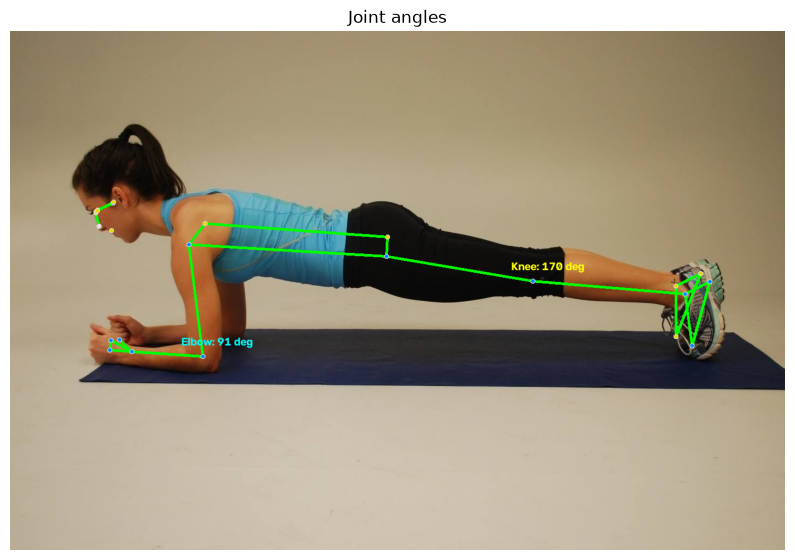

In [21]:
# Cell 9 — Elbow and knee angles + visualization
def draw_angle_text(image, text, position, color=(255, 255, 0)):
    cv2.putText(image, text, position, cv2.FONT_HERSHEY_SIMPLEX,
                0.7, color, 2, cv2.LINE_AA)

if detection_result.pose_landmarks:
    lm = detection_result.pose_landmarks[0]
    h, w = rgb.shape[:2]

    # Left elbow: shoulder → elbow → wrist
    shoulder = get_landmark(lm, "LEFT_SHOULDER")
    elbow    = get_landmark(lm, "LEFT_ELBOW")
    wrist    = get_landmark(lm, "LEFT_WRIST")
    elbow_angle = calculate_angle(shoulder, elbow, wrist)

    # Left knee: hip → knee → ankle
    hip   = get_landmark(lm, "LEFT_HIP")
    knee  = get_landmark(lm, "LEFT_KNEE")
    ankle = get_landmark(lm, "LEFT_ANKLE")
    knee_angle = calculate_angle(hip, knee, ankle)

    print(f"Left elbow angle: {elbow_angle:.1f}°")
    print(f"Left knee angle : {knee_angle:.1f}°")

    # Visualize
    annotated = draw_pose(rgb, detection_result)
    # Convert to BGR for OpenCV text if needed, but we stay in RGB for matplotlib
    annotated_bgr = cv2.cvtColor(annotated, cv2.COLOR_RGB2BGR)
    draw_angle_text(annotated_bgr, f"Elbow: {elbow_angle:.0f} deg",
                    (int(elbow[0]*w)-40, int(elbow[1]*h)-20))
    draw_angle_text(annotated_bgr, f"Knee: {knee_angle:.0f} deg",
                    (int(knee[0]*w)-40, int(knee[1]*h)-20), color=(0, 255, 255))
    annotated_rgb = cv2.cvtColor(annotated_bgr, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 8))
    plt.imshow(annotated_rgb)
    plt.title("Joint angles")
    plt.axis("off")
    plt.show()

**Key insight**  
We can now describe a pose *numerically*.

---
## Section 9 — From Geometry to Body State

**Question**  
If we know the angles and positions, can we describe what the person is doing?

We use simple rule-based logic (no machine learning).

In [22]:
# Cell 10 — Simple body-state classification
def classify_pose(landmarks):
    """Return a simple description of the current body state."""
    left_shoulder = get_landmark(landmarks, "LEFT_SHOULDER")
    right_shoulder = get_landmark(landmarks, "RIGHT_SHOULDER")
    left_wrist = get_landmark(landmarks, "LEFT_WRIST")
    right_wrist = get_landmark(landmarks, "RIGHT_WRIST")
    left_hip = get_landmark(landmarks, "LEFT_HIP")
    left_knee = get_landmark(landmarks, "LEFT_KNEE")
    left_ankle = get_landmark(landmarks, "LEFT_ANKLE")

    # Arms raised if wrists are above shoulders (smaller y = higher in image)
    left_arm_up  = left_wrist[1] < left_shoulder[1] - 0.05
    right_arm_up = right_wrist[1] < right_shoulder[1] - 0.05

    # Knee angle for standing vs bent
    knee_ang = calculate_angle(left_hip, left_knee, left_ankle)

    if knee_ang > 160:
        lower_body = "Standing"
    elif knee_ang > 100:
        lower_body = "Slightly bent"
    else:
        lower_body = "Deep bend / Sitting-like"

    arms = []
    if left_arm_up and right_arm_up:
        arms.append("Both arms raised")
    elif left_arm_up:
        arms.append("Left arm raised")
    elif right_arm_up:
        arms.append("Right arm raised")
    else:
        arms.append("Arms down")

    return {
        "lower_body": lower_body,
        "arms": ", ".join(arms),
        "knee_angle": round(knee_ang, 1)
    }

if detection_result.pose_landmarks:
    state = classify_pose(detection_result.pose_landmarks[0])
    print("Body state:")
    for k, v in state.items():
        print(f"  {k}: {v}")

Body state:
  lower_body: Standing
  arms: Arms down
  knee_angle: 169.8


---
## Section 10 — Position vs Movement

A pose describes a state at **one moment**.  
Movement requires **multiple moments**.



---
## Section 11 — Analyze Movement (Conceptual Demo)

We simulate a short sequence of wrist positions to illustrate the idea.

In [23]:
# Cell 11 — Simulated movement analysis
# Imagine wrist y-coordinates over 4 frames (smaller y = higher in image)
wrist_y_sequence = [0.70, 0.55, 0.40, 0.30]  # rising hand

print("Wrist vertical position over frames:")
for i, y in enumerate(wrist_y_sequence, 1):
    print(f"  Frame {i}: y = {y:.2f}")

deltas = np.diff(wrist_y_sequence)
print("\nPosition changes (delta y):", deltas)
print("Overall direction: upward" if np.mean(deltas) < 0 else "Overall direction: downward")
print("Approximate speed (avg |delta|):", np.mean(np.abs(deltas)))

Wrist vertical position over frames:
  Frame 1: y = 0.70
  Frame 2: y = 0.55
  Frame 3: y = 0.40
  Frame 4: y = 0.30

Position changes (delta y): [-0.15 -0.15 -0.1 ]
Overall direction: upward
Approximate speed (avg |delta|): 0.13333333333333333


**Checkpoint**  
Can one frame tell us whether someone is moving?  
What is the difference between a pose and a movement?

---
## Section 12 — Detect Simple Movements

We start with a conceptually simple movement: **hand raise**.  
Then we move to the more interesting **squat**.

In [25]:
# Cell 12 — Simple hand-raise detector (single frame rule)
def is_hand_raised(landmarks, side="LEFT"):
    shoulder = get_landmark(landmarks, f"{side}_SHOULDER")
    wrist    = get_landmark(landmarks, f"{side}_WRIST")
    # Wrist significantly above shoulder
    return wrist[1] < shoulder[1] - 0.08

if detection_result.pose_landmarks:
    lm = detection_result.pose_landmarks[0]
    print("Left hand raised :", is_hand_raised(lm, "LEFT"))
    print("Right hand raised:", is_hand_raised(lm, "RIGHT"))

Left hand raised : False
Right hand raised: False


---
## Section 13 — Squat as a Puzzle

**Question**  
How could a computer know that someone completed one squat?

We break the movement into states:

```mermaid
stateDiagram-v2
    [*] --> Standing
    Standing --> GoingDown: knee angle decreases
    GoingDown --> Bottom: knee angle < threshold
    Bottom --> GoingUp: knee angle increases
    GoingUp --> Standing: knee angle > threshold
    Standing --> Standing: count +1 (after full cycle)
```

A person staying at the bottom for many frames must **not** count as many squats.  
State transitions are essential.

---
## Section 14 — Squat Counter (Rule-Based State Machine)

In [26]:
# Cell 13 — Squat state machine
class SquatCounter:
    def __init__(self, down_thresh=100, up_thresh=140):
        self.state = "standing"
        self.count = 0
        self.down_thresh = down_thresh
        self.up_thresh = up_thresh

    def update(self, knee_angle):
        if self.state == "standing":
            if knee_angle < self.up_thresh - 15:   # started going down
                self.state = "going_down"
        elif self.state == "going_down":
            if knee_angle < self.down_thresh:
                self.state = "bottom"
        elif self.state == "bottom":
            if knee_angle > self.down_thresh:
                self.state = "going_up"
        elif self.state == "going_up":
            if knee_angle > self.up_thresh:
                self.state = "standing"
                self.count += 1
        return self.state, self.count
    
# Demonstration with a synthetic squat sequence of knee angles
demo_angles = [170, 165, 150, 130, 105, 95, 100, 120, 145, 165, 172]
counter = SquatCounter()
print("Frame | Knee Angle | State        | Count")
print("-" * 45)
for i, ang in enumerate(demo_angles, 1):
    state, count = counter.update(ang)
    print(f"{i:5d} | {ang:10.0f} | {state:12s} | {count}")

Frame | Knee Angle | State        | Count
---------------------------------------------
    1 |        170 | standing     | 0
    2 |        165 | standing     | 0
    3 |        150 | standing     | 0
    4 |        130 | standing     | 0
    5 |        105 | going_down   | 0
    6 |         95 | bottom       | 0
    7 |        100 | bottom       | 0
    8 |        120 | going_up     | 0
    9 |        145 | standing     | 1
   10 |        165 | standing     | 1
   11 |        172 | standing     | 1


**Why states matter**  
A person remaining at the bottom for 20 frames should not produce 20 squat counts.  
Only a complete transition cycle increments the counter.

---
## Section 15 — Real-Time Webcam Pipeline

Only after understanding the image-based logic do we move to video.



In [27]:
# Cell 14 — Helper for video mode (re-create landmarker in VIDEO mode)
def create_video_landmarker(model_path=MODEL_PATH):
    options = PoseLandmarkerOptions(
        base_options=BaseOptions(model_asset_path=str(model_path)),
        running_mode=VisionRunningMode.VIDEO,
        num_poses=1
    )
    return PoseLandmarker.create_from_options(options)

---
## Section 16 — Real-Time Pose Analyzer (Mini Project)

The final application displays a readable summary each frame:

```
Pose: Standing
Left Arm: Raised
Right Arm: Down
Knee Angle: 91°
Movement: Stable
Squats: 3
```

In [38]:
# Cell 15 — Pose Analyzer + Squat Counter (video file)
# Place a video file in the current directory.
# Press q to quit early.

def run_pose_analyzer(video_path="Sumo_Squat_GIF.gif"):
    landmarker_video = create_video_landmarker()
    squat_counter = SquatCounter(down_thresh=100, up_thresh=140)
    prev_knee = None
    frame_idx = 0

    # Smooth movement detection
    movement_history = []
    MOVING_ENTER = 4.0
    MOVING_EXIT = 1.5
    HISTORY_LEN = 5
    is_moving = False

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print(f"Cannot open video: {video_path}")
        return

    print("Pose Analyzer running on video. Press q to quit.")

    try:
        while True:
            ret, frame = cap.read()
            if not ret:
                break

            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_rgb)

            timestamp_ms = int(cap.get(cv2.CAP_PROP_POS_MSEC))
            if timestamp_ms <= 0:
                timestamp_ms = frame_idx * 33
            frame_idx += 1

            result = landmarker_video.detect_for_video(mp_image, timestamp_ms)

            display = frame.copy()
            info_lines = []

            if result.pose_landmarks:
                annotated = draw_pose(frame_rgb, result)
                display = cv2.cvtColor(annotated, cv2.COLOR_RGB2BGR)

                lm = result.pose_landmarks[0]
                state = classify_pose(lm)

                hip = get_landmark(lm, "LEFT_HIP")
                knee = get_landmark(lm, "LEFT_KNEE")
                ankle = get_landmark(lm, "LEFT_ANKLE")
                knee_ang = calculate_angle(hip, knee, ankle)

                squat_state, squat_count = squat_counter.update(knee_ang)

                # Smooth movement with hysteresis
                movement = "Stable"
                if prev_knee is not None:
                    delta = abs(knee_ang - prev_knee)
                    movement_history.append(delta)
                    if len(movement_history) > HISTORY_LEN:
                        movement_history.pop(0)

                    avg_delta = sum(movement_history) / len(movement_history)

                    if not is_moving and avg_delta > MOVING_ENTER:
                        is_moving = True
                    elif is_moving and avg_delta < MOVING_EXIT:
                        is_moving = False

                    if is_moving:
                        movement = "Fast" if avg_delta > 12 else "Moving"
                    else:
                        movement = "Stable"

                prev_knee = knee_ang

                info_lines = [
                    f"Pose: {state['lower_body']}",
                    f"Arms: {state['arms']}",
                    f"Knee: {knee_ang:.0f} deg",
                    f"Squat state: {squat_state}",
                    f"Squats: {squat_count}",
                    f"Movement: {movement}"
                ]
            else:
                info_lines = ["No pose detected"]

            y0 = 30
            for i, line in enumerate(info_lines):
                cv2.putText(display, line, (10, y0 + i * 28),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2)

            cv2.imshow("Pose Analyzer", display)

            if cv2.waitKey(1) & 0xFF == ord("q"):
                break
    finally:
        cap.release()
        cv2.destroyAllWindows()
        landmarker_video.close()
        print("Video finished. Done.")

# Uncomment the next line to run
run_pose_analyzer("Sumo_Squat_GIF.gif")

Pose Analyzer running on video. Press q to quit.
Video finished. Done.


**Note**  
The cell above is commented so the notebook can be executed top-to-bottom without a camera.  
Uncomment `run_pose_analyzer()` when you are ready to test with a webcam.

---
## Section 17 — Practical Applications

| Domain | Example | Useful landmarks / features |
|--------|---------|-----------------------------|
| Fitness | Squat / push-up counter, form feedback | Knee, hip, elbow angles; vertical position changes |
| HCI | Touchless control, body gestures | Wrist / shoulder relative positions |
| Accessibility | Alternative input methods | Large, reliable body movements |
| Sports | Basic technique visualization | Joint angles, symmetry |
| Education | Interactive movement demos | Clear skeleton + angle overlays |
| Gaming | Body-controlled interaction | Pose states + movement direction |
| Robotics | Human movement as control signal | World landmarks, trajectories |

The same pipeline (landmarks → geometry → state → movement) can be reused for many applications.

---
## Appendix — Landmark Index Quick Reference

```
0  nose
11 left shoulder   12 right shoulder
13 left elbow      14 right elbow
15 left wrist      16 right wrist
23 left hip        24 right hip
25 left knee       26 right knee
27 left ankle      28 right ankle
```

Full list of 33 landmarks is available in the official MediaPipe documentation.